<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/29_Adversarial_Robustness_Defences_for_QML/QNN_AdversarialRobustness_Tran2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# Quantum patches against adversarial attacks: Tran et al. (2026) step by step

This notebook re-implements, runs and checks the method of

> Ban Q. Tran, Chuong K. Luong, Viet Q. Nguyen, Duong M. Chu and Susan Mengel,
> "Quantum Patches: Enhancing Robustness of Quantum Machine Learning Models",
> arXiv:2604.08827 [quant-ph], 9 April 2026. https://doi.org/10.48550/arxiv.2604.08827

The authors point to their code ("QDAA-2025") but the paper text we work from only gives the recipe, so everything below is written
from that recipe, with the same stack the paper names (PennyLane, with automatic differentiation; we use PyTorch instead of JAX/Optax).

**What the notebook does.** It builds the paper's victim, a 4-qubit *circuit-centric quantum classifier with data re-uploading*, attacks it
with the fast gradient sign method (FGSM, epsilon = 0.1) and then adds the paper's defence, the **quantum patch**: a fixed *random
quantum circuit* (RQC) is slid over 2x2 patches of the image like a convolution filter (a "quanvolution") and produces four extra
channels that are stacked on the original image. It trains the plain and the defended model on MNIST (digits 0 vs 1), CIFAR-10 (cat vs dog) and
CINIC-10 (cat vs dog), measures clean accuracy, adversarial accuracy and attack success rate (the paper's Table 1), and repeats the
paper's ablation against ordinary adversarial training (Lipschitz bound, Fig. 9; average fidelity, Fig. 10). A small classical network and
scikit-learn models on the identical inputs serve as baselines.

**How to run it.** Open in Colab (badge above), choose a CPU runtime, and use *Runtime -> Run all*. The first cell installs a pinned PennyLane;
if Colab asks you to restart the session, restart and run all again. No GPU, no IBM Quantum account and no token are needed.

**Runtime.** `FAST_MODE = True` (60 training and 50 test images per dataset, 5 epochs, one seed) takes about 5 minutes on a laptop CPU. `FAST_MODE = False`
(240 training and 200 test images per dataset, 25 epochs, three seeds) is the committed run: about 51 minutes in total on a shared laptop CPU (2 torch threads), of which about 40 minutes are the 27 training runs (the time is printed under the training cell). The paper's own budget (full-size images, 50 epochs, about 48 hours on four H100 GPUs per model) is not
reachable on a CPU simulator, so the numbers are **not** expected to match the paper's absolutely: the notebook tests whether the paper's *qualitative* claims survive in a small, honest
replication.

**What you get at the end.** The paper's Table 1 re-computed (clean accuracy and attack success rate with and without quantum patches), the
epsilon sweep, PGD as a stronger attack, the Lipschitz and fidelity ablation, classical baselines, and a claim-by-claim verdict table.


## The paper in one page

**Problem.** Quantum machine learning (QML) models are as fragile as classical networks: a tiny, crafted perturbation of the input (an *adversarial
example*) flips the prediction. The paper asks whether the physics of quantum circuits can supply a cheap defence.

**Decision.** Binary image classification on three image sets; the attacker is white box and uses the loss gradient (FGSM, Eq. 2) with epsilon = 0.1 on the pixel range.

**Method ("quantum patches").** (1) Cut the image into small patches (here 2x2 = 4 pixels). (2) Encode the four pixels of a patch as rotation angles of four qubits.
(3) Apply a *random quantum circuit* (RQC) that is drawn once and then kept fixed. (4) Measure the four qubits; the four expectation values become four output
*channels* (Fig. 6), "pseudo-noise" that is meant to mimic what an adversarial attack does to an image. (5) Stack the original image with these four channels
(Fig. 7) and train the quantum classifier on the result, so that the model has already seen a quantum-generated perturbation of the data when the real attacker
arrives. The classifier is the *circuit-centric quantum classifier* of Schuld et al. (PennyLane `StronglyEntanglingLayers`, Pauli-Z read-out, data re-uploading) with cross-entropy loss.

**Data.** Plus-Minus (1,000 tiny images, PennyLane), MNIST digits 0 and 1, CIFAR-10 cat vs dog, CINIC-10 cat vs dog.

**Metrics.** Adversarial accuracy AA (Eq. 5), attack success rate ASR (Eq. 6), the Lipschitz bound of the model (Eq. 7-8, Berberich et al.) and the average fidelity
between the output states for clean and adversarial inputs (Eq. 9).

**Claims.**

| Dataset | Clean AA, plain | Clean AA, with RQC | ASR (eps = 0.1), plain | ASR (eps = 0.1), with RQC |
|---|---|---|---|---|
| MNIST 0 vs 1 | 100 % | 88 % (-12) | 22 % | 25.38 % (+3.58, no help) |
| CIFAR-10 cat vs dog | 48 % | 45 % (-3) | 89.8 % | 68.45 % (-21.35) |
| CINIC-10 cat vs dog | 57 % | 47 % (-10) | 94.23 % | 78.68 % (-15.55) |

Further claims: with RQC the Lipschitz bound after 50 epochs on CIFAR-10 is 0.571 against 0.711 for an adversarially trained baseline (Fig. 9); the average fidelity between clean and adversarial
output states stays closer to 1 as epsilon grows (Fig. 10); on Plus-Minus the model gets 4/4 clean, 0/4 under attack and 3/4 with RQC (Fig. 8); a QCNN victim improves "less pronouncedly"
(no numbers). The abstract says RQC data "provides a similar effect to models trained with adversarial data on high-feature datasets".

The text of Table 1 in the PDF is garbled when extracted. We read the rows as above: the "clean images" rows are accuracies, the "adversarial examples" rows are attack success rates
(the paper's own text says "the ASR actually increased from 22% to 25.38%" for MNIST and "decreased from 89.8% to 68.45%" for CIFAR-10).

## What follows the paper and what had to be chosen

The paper does not publish its hyper-parameters in the text, trains for about 48 GPU hours per model, and does not say how the images were prepared. Every
item below that is not given by the paper is a choice made here and marked `# CHOICE:` in the code.

| Item | Paper | This notebook |
|---|---|---|
| Framework | PennyLane + JAX + Optax | PennyLane 0.45.1 (`default.qubit`, backprop) + PyTorch + Adam |
| Victim model | Circuit-centric classifier, `StronglyEntanglingLayers`, Pauli-Z read-out, re-uploading of m x m patches | 4 qubits; one `AngleEmbedding(RY)` + one `StronglyEntanglingLayers` layer per 2x2 patch (16 blocks for an 8x8 image, 32 with quantum patches); logits = 3 x <Z0>, <Z1> |
| Angle of the encoding | Not stated ("angle rotation embedding") | Pixel in [0, 1] used directly as a rotation angle in radians (`ENC_SCALE = 1`), times a trainable scale per block. A pilot with angles in [0, pi] made the model so fragile that FGSM overshoots; that setting is run as a sensitivity check in section 7b. **Disclosure:** the value 1.0 was chosen after this small pilot (one seed, MNIST/CIFAR-10), i.e. after seeing that it behaves more like the paper on MNIST; it is one tuned hyper-parameter, not a blind choice |
| Quantum patch (RQC) | Random circuit on 4 qubits, "Haar-like", unspecified depth; 4 output channels | `AngleEmbedding(RY(pi x))` on 4 qubits + `RandomLayers` (2 layers, fixed seed), <Z> on every qubit; non-overlapping 2x2 patches (stride 2) |
| How the patches enter the model | "Combined with the original data", original image + 4 channels (Fig. 7) | Same: the 4 channels (IMG/2 x IMG/2) are cut into 2x2 blocks and re-uploaded after the image blocks. The channels are recomputed from the perturbed input, so the white-box attack goes **through** the RQC |
| Images | Full size (28x28 MNIST, 32x32 colour) | Grey, area-averaged down to 8x8 (64 pixels) so that a CPU simulator can differentiate through the circuit |
| Sample sizes | Full data sets, 50 epochs | 120 + 120 training and 100 + 100 test images per dataset, 25 epochs, three seeds |
| CINIC-10 | train / validation / test (90,000 each) | Only the 257 MB Hugging Face *test* parquet is downloaded; training and test images are disjoint random draws from it |
| Attack | FGSM, epsilon = 0.1 (also an "epsilon sweep" in Fig. 10) | FGSM, epsilon = 0.1, plus a sweep 0 to 0.2 and a 10-step PGD as an extra, stronger attack (not in the paper) |
| ASR | "share of adversarial examples classified wrongly" | `ASR = 1 - AA` on all test images; additionally `ASR of correct` = share of originally correct images that flip |
| Baseline of the ablation | Quantum classifier retrained with perturbed images | FGSM adversarial training, epsilon = 0.1, each batch doubled with fresh FGSM examples |
| Lipschitz bound | Eq. 8, values 0.571 and 0.711 at epoch 50 | Eq. 8 with trainable per-block encoding scales; the absolute scale depends on the encoding and is not comparable with the paper |
| Average fidelity | Clean vs adversarial state | `|<psi_adv|psi_clean>|^2` of the final pre-measurement states, averaged over test images |
| Plus-Minus | PennyLane data set | Not run (the dataset is not obtainable here) |
| QCNN victim | Mentioned, no numbers | Not run |
| Hardware / noise | Simulator only | Simulator only (`IBM_TOKEN` unused) |


## 0. Setup


In [1]:
# Versions tested with this notebook (October 2026). Colab already ships torch, numpy, pandas, scikit-learn, matplotlib,
# pyarrow and huggingface_hub. The pip line runs on Colab (or wherever PennyLane is missing); a prepared local environment is left untouched.
import importlib.util, sys
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or importlib.util.find_spec("pennylane") is None:
    %pip install -q "pennylane==0.45.1" pyarrow huggingface_hub
    if importlib.util.find_spec("torch") is None:
        %pip install -q torch --index-url https://download.pytorch.org/whl/cpu
    print("Packages installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("PennyLane already present; skipping pip install.")


PennyLane already present; skipping pip install.


The next cell holds **every tunable constant**. `FAST_MODE = True` gives a few-minute class demo; `False` is the committed run described above.
The paper's own budget (full images, 50 epochs, about 48 h per model on four H100 GPUs) is out of reach on a CPU, so the full path of this notebook is itself a reduced replication; each reduction is a `# CHOICE:` line.


In [2]:
# ---------------- configuration ----------------
FAST_MODE = False           # True: class demo, a few minutes. False: the full (still reduced) budgets documented above.

SEED  = 42                  # CHOICE: the paper gives no seed. Controls data sampling, weights init, batching, the RQC circuit.
SEEDS = [42] if FAST_MODE else [42, 43, 44]     # CHOICE: independent repetitions (data subset fixed, model/RQC/batch seeds vary)

# --- data (paper: full MNIST 0/1, CIFAR-10 cat/dog, CINIC-10 cat/dog) ---
DATASETS = ["MNIST", "CIFAR10", "CINIC10"]      # paper Table 1 rows
IMG = 8                                          # CHOICE: images are down-scaled to IMG x IMG grey pixels (paper: full size)
N_TRAIN_PER_CLASS = 30 if FAST_MODE else 120     # CHOICE: a few hundred images in total, a CPU simulator cannot do more
N_TEST_PER_CLASS  = 25 if FAST_MODE else 100
DATA_DIR = "data"                                # cached downloads (relative to the working directory)

# --- quantum classifier (circuit-centric, data re-uploading, 4 qubits, StronglyEntanglingLayers) ---
N_QUBITS     = 4            # paper: four qubits (one 2x2 patch per block)
ENC_SCALE    = 1.0          # CHOICE: rotation angle = ENC_SCALE * enc_b * pixel, i.e. raw pixels in [0,1] as angles (PennyLane AngleEmbedding default).
                            #   Pilot runs showed 3.14159 (pixels -> [0, pi]) makes the model so sensitive that FGSM overshoots; see section 7b
LOGIT_SCALE  = 3.0          # CHOICE: logits = LOGIT_SCALE * <Z_q> for q in {0,1} (binary tasks)
EPOCHS       = 5 if FAST_MODE else 25        # paper: 50 epochs of ~48 h on 4 H100 GPUs; CHOICE here
BATCH        = 30 if FAST_MODE else 80       # CHOICE
LR           = 0.05         # CHOICE: Adam learning rate

# --- quantum patches (random quantum circuit, "quanvolution") ---
RQC_LAYERS   = 2            # CHOICE: RandomLayers depth (paper: "unspecified circuit depth", Haar-like unitary)
RQC_RATIO_IMPRIM = 0.3      # CHOICE: share of two-qubit gates in the random layers (PennyLane default)
RQC_ENC_SCALE = 3.141592653589793   # CHOICE: the random circuit sees pixels as angles in [0, pi] (as in the quanvolution tutorial)
RQC_N_CHANNELS = 4          # paper: four output channels (= four qubits)

# --- attacks ---
EPS_MAIN   = 0.1            # paper: epsilon = 0.1 (pixel range [0, 1])
EPS_GRID   = [0.0, 0.01, 0.025, 0.05, 0.1, 0.2]    # CHOICE: epsilon sweep for the fidelity / robustness curves
ADV_TRAIN_EPS = 0.1         # CHOICE: epsilon used by the adversarial-training baseline of the ablation
PGD_STEPS  = 5 if FAST_MODE else 10          # CHOICE: extra iterative attack (the paper uses FGSM-type noise only)

N_THREADS  = 2              # CPU threads for torch (be kind to a shared machine)
IBM_TOKEN  = ""             # unused: the paper is simulator-only (kept for the factory's conventions)


In [3]:
import os, io, time, math, copy, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

import torch
import torch.nn.functional as F
import pennylane as qml
import sklearn
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression

torch.set_num_threads(N_THREADS)
torch.manual_seed(SEED)
rng = np.random.default_rng(SEED)
os.makedirs(DATA_DIR, exist_ok=True)
pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 80)

print("pennylane", qml.__version__, "| torch", torch.__version__, "| numpy", np.__version__,
      "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__)
print("FAST_MODE =", FAST_MODE, "| seeds =", SEEDS, "| datasets =", DATASETS)


pennylane 0.45.1 | torch 2.14.1+cpu | numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1
FAST_MODE = False | seeds = [42, 43, 44] | datasets = ['MNIST', 'CIFAR10', 'CINIC10']


## 1. Data: three binary image tasks

The paper uses three public image sets: MNIST (handwritten digits 0 and 1), CIFAR-10 (cat versus dog) and CINIC-10 (cat versus dog, an enlarged CIFAR-10 that
adds down-sampled ImageNet images). The notebook fetches them from Hugging Face mirrors (parquet files with PNG bytes), caches them in `DATA_DIR`, and falls back to
`tf.keras.datasets` for MNIST and CIFAR-10 if the Hugging Face download fails.

Because the quantum circuit is differentiated on a CPU simulator, each image is converted to grey and area-averaged down to **8 x 8 pixels** (64 numbers in [0, 1]); a random, class-balanced
subset is drawn. There is nothing to fit on the training split here (no scaler, no PCA), so no information can leak from the test set; the hyper-parameters (learning rate, epochs, circuit depth) were fixed
in advance and not tuned on the test images. The Plus-Minus set of the paper is not reproduced (see the table above).


Loading data (the first run downloads; later runs use the cache in DATA_DIR) ...


  MNIST    train (240, 8, 8) test (200, 8, 8) from Hugging Face ylecun/mnist in 1s; classes ('0', '1'), train balance [120, 120]


  CIFAR10  train (240, 8, 8) test (200, 8, 8) from Hugging Face uoft-cs/cifar10 in 1s; classes ('cat', 'dog'), train balance [120, 120]


  CINIC10  train (240, 8, 8) test (200, 8, 8) from Hugging Face flwrlabs/cinic10 in 2s; classes ('cat', 'dog'), train balance [120, 120]


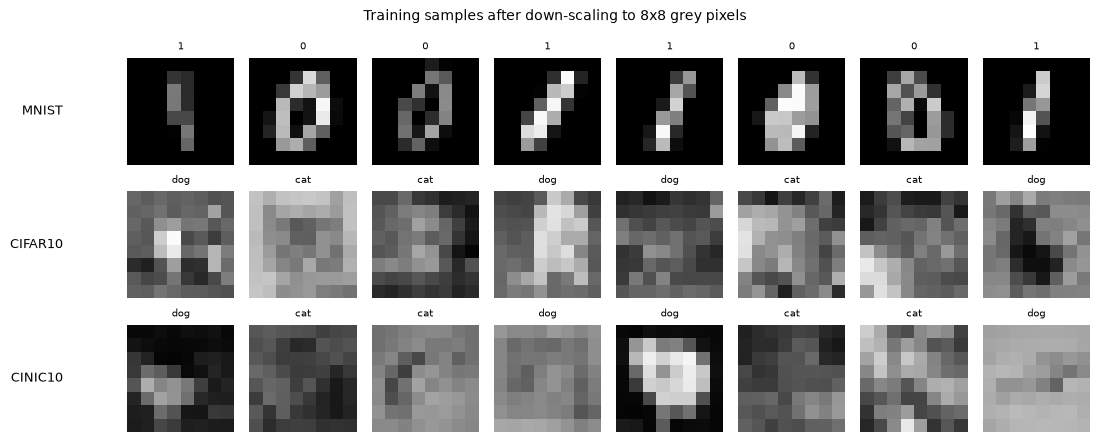

In [4]:
import pyarrow.parquet as pq
from PIL import Image
from huggingface_hub import hf_hub_download

# Hugging Face mirrors (parquet files with PNG bytes). CINIC-10: only the 257 MB "test" parquet is fetched.
SOURCES = {
    "MNIST":   dict(repo="ylecun/mnist",     train="mnist/train-00000-of-00001.parquet",
                    test="mnist/test-00000-of-00001.parquet", img="image", classes=(0, 1), names=("0", "1")),
    "CIFAR10": dict(repo="uoft-cs/cifar10",  train="plain_text/train-00000-of-00001.parquet",
                    test="plain_text/test-00000-of-00001.parquet", img="img", classes=(3, 5), names=("cat", "dog")),
    "CINIC10": dict(repo="flwrlabs/cinic10", train="data/test-00000-of-00001.parquet",
                    test="data/test-00000-of-00001.parquet", img="image", classes=(3, 5), names=("cat", "dog")),
}

def decode(field):
    """PNG bytes -> grey image, area-averaged down to IMG x IMG, pixels in [0, 1]."""
    raw = field["bytes"] if isinstance(field, dict) else field
    im = Image.open(io.BytesIO(raw)).convert("L").resize((IMG, IMG), Image.BOX)
    return np.asarray(im, dtype=np.float64) / 255.0

def sample_split(path, img_col, classes, n_per_class, rs, exclude=None):
    """Class-balanced random rows of a parquet file; returns images (N, IMG, IMG), binary labels (N,), used row ids."""
    table = pq.read_table(path)
    labels = np.asarray(table.column("label").to_pylist())
    rows, ys = [], []
    for k, c in enumerate(classes):
        ids = np.flatnonzero(labels == c)
        if exclude is not None:
            ids = np.setdiff1d(ids, exclude)
        pick = rs.choice(ids, size=n_per_class, replace=False)
        rows += list(pick); ys += [k] * n_per_class
    col = table.column(img_col).take(rows).to_pylist()
    X = np.stack([decode(f) for f in col]); y = np.asarray(ys)
    order = rs.permutation(len(y))
    return X[order], y[order], np.asarray(rows)

def keras_fallback(name):
    """Fallback for MNIST / CIFAR-10 only: tf.keras.datasets (Colab ships TensorFlow)."""
    from tensorflow.keras import datasets as kd
    (xtr, ytr), (xte, yte) = (kd.mnist if name == "MNIST" else kd.cifar10).load_data()
    return (xtr, ytr.ravel()), (xte, yte.ravel())

def load_dataset(name, seed):
    s = SOURCES[name]; rs = np.random.default_rng(seed)
    t0 = time.time()
    try:
        ptr = hf_hub_download(s["repo"], s["train"], repo_type="dataset", cache_dir=DATA_DIR)
        pte = hf_hub_download(s["repo"], s["test"],  repo_type="dataset", cache_dir=DATA_DIR)
        Xtr, ytr, used = sample_split(ptr, s["img"], s["classes"], N_TRAIN_PER_CLASS, rs)
        same_file = (ptr == pte)
        Xte, yte, _ = sample_split(pte, s["img"], s["classes"], N_TEST_PER_CLASS, rs, exclude=used if same_file else None)
        src = "Hugging Face " + s["repo"]
    except Exception as e:                         # pragma: no cover - network fallback
        if name == "CINIC10":
            print(f"  {name}: download failed ({type(e).__name__}); dataset skipped"); return None
        print(f"  {name}: HF download failed ({type(e).__name__}); using tf.keras.datasets")
        (xtr, ytr), (xte, yte) = keras_fallback(name)
        def take(x, y, n):
            sel = np.concatenate([rs.choice(np.flatnonzero(y == c), n, replace=False) for c in s["classes"]])
            sel = rs.permutation(sel)
            xs = x[sel] if x.ndim == 3 else np.stack([np.asarray(Image.fromarray(a).convert("L")) for a in x[sel]])
            xs = np.stack([np.asarray(Image.fromarray(a.astype(np.uint8)).resize((IMG, IMG), Image.BOX)) for a in xs]) / 255.0
            return xs, (y[sel] == s["classes"][1]).astype(int)
        Xtr, ytr = take(xtr, ytr, N_TRAIN_PER_CLASS); Xte, yte = take(xte, yte, N_TEST_PER_CLASS)
        src = "tf.keras.datasets"
    print(f"  {name:8s} train {Xtr.shape} test {Xte.shape} from {src} in {time.time()-t0:.0f}s; "
          f"classes {s['names']}, train balance {np.bincount(ytr).tolist()}")
    return dict(Xtr=Xtr, ytr=ytr, Xte=Xte, yte=yte, names=s["names"])

print("Loading data (the first run downloads; later runs use the cache in DATA_DIR) ...")
DATA = {}
for name in DATASETS:
    d = load_dataset(name, SEED)
    if d is not None:
        DATA[name] = d
DATASETS = [n for n in DATASETS if n in DATA]

fig, axes = plt.subplots(len(DATASETS), 8, figsize=(11, 1.5 * len(DATASETS)))
axes = np.atleast_2d(axes)
for r, name in enumerate(DATASETS):
    d = DATA[name]
    for c in range(8):
        axes[r, c].imshow(d["Xtr"][c], cmap="gray", vmin=0, vmax=1); axes[r, c].axis("off")
        axes[r, c].set_title(d["names"][d["ytr"][c]], fontsize=7)
    axes[r, 0].text(-0.6, 0.5, name, transform=axes[r, 0].transAxes, ha="right", va="center", fontsize=9)
plt.suptitle(f"Training samples after down-scaling to {IMG}x{IMG} grey pixels", fontsize=10); plt.tight_layout(); plt.show()


## 2. The victim: a circuit-centric quantum classifier with data re-uploading

The classifier of Schuld, Bocharov, Svore and Wiebe (the paper's reference [38]) is a *parametrised quantum circuit* with *angle encoding*. Because 64 pixels do not fit in 4 qubits, the pixels are
fed in *chunks* (this is the "re-uploading" of the paper): the image is cut into 16 non-overlapping 2x2 patches, and for every patch the circuit does

1. `AngleEmbedding(rotation="Y")`: four rotations `RY(ENC_SCALE * enc_b * x_i)`, one per qubit (`ENC_SCALE = 1`: the pixel value in [0, 1] is the angle in radians); `enc_b` is a trainable scale (initialised to 1), which also makes the Lipschitz bound of Eq. 8 non-trivial;
2. one `StronglyEntanglingLayers` layer (3 rotation angles per qubit followed by a ring of CNOTs), 12 trainable weights.

After the last block the Pauli-Z expectation values of qubits 0 and 1 are the two class scores (times `LOGIT_SCALE`) and the cross-entropy loss is minimised with Adam. The model is simulated exactly
on `default.qubit` with backpropagation, so the *input gradient* needed by FGSM comes for free from PyTorch autograd.

With the **quantum patches** the same chain gets 16 more blocks: the four channels produced by the random circuit (each 4x4 numbers) are cut into 2x2 blocks and uploaded after the image blocks.
The random circuit itself, `QuantumPatches`, is the quanvolution filter of Henderson et al. (the paper's reference [43]): angle-encode a 2x2 patch on four qubits, apply a fixed random circuit (PennyLane `RandomLayers`: random single-qubit
rotations and CNOTs drawn from a seed), measure `<Z>` on all four qubits, and map the four values in [-1, 1] to [0, 1]. The circuit is drawn once (per seed) and never trained.


In [5]:
DTYPE = torch.float64
dev = qml.device("default.qubit", wires=N_QUBITS)

def image_to_blocks(img):
    """(B, IMG, IMG) -> (B, (IMG/2)^2, 4): every non-overlapping 2x2 patch becomes one block of 4 numbers."""
    B, h = img.shape[0], IMG // 2
    return img.reshape(B, h, 2, h, 2).permute(0, 1, 3, 2, 4).reshape(B, h * h, 4)

def channels_to_blocks(ch):
    """(B, C, IMG/2, IMG/2) -> (B, C*(IMG/4)^2, 4): the same 2x2 patching for each quanvolution channel."""
    B, C, h = ch.shape[0], ch.shape[1], IMG // 4
    return ch.reshape(B, C, h, 2, h, 2).permute(0, 1, 2, 4, 3, 5).reshape(B, C * h * h, 4)

def circuit_body(blocks, weights, enc):
    """Circuit-centric classifier with data re-uploading.
    block b: angle embedding RY(ENC_SCALE * enc_b * x) of 4 numbers, then one StronglyEntanglingLayers layer (12 weights)."""
    for b in range(blocks.shape[1]):
        qml.AngleEmbedding(ENC_SCALE * enc[b] * blocks[:, b, :], wires=range(N_QUBITS), rotation="Y")
        qml.StronglyEntanglingLayers(weights[b], wires=range(N_QUBITS))

@qml.qnode(dev, interface="torch", diff_method="backprop")
def logits_circuit(blocks, weights, enc):
    circuit_body(blocks, weights, enc)
    return qml.expval(qml.PauliZ(0)), qml.expval(qml.PauliZ(1))

@qml.qnode(dev, interface="torch", diff_method="backprop")
def state_circuit(blocks, weights, enc):
    circuit_body(blocks, weights, enc)
    return qml.state()

# ---- the quantum patch: a fixed random circuit slid over 2x2 patches (quanvolution, Henderson et al. 2020) ----
class QuantumPatches:
    """Encodes a 2x2 patch with RY(RQC_ENC_SCALE*x) on 4 qubits, applies a fixed random circuit U, measures <Z> on every qubit.
    Four numbers out per patch = four channels; non-overlapping patches halve the resolution (IMG -> IMG/2)."""
    def __init__(self, seed):
        self.seed = seed
        r = np.random.default_rng(10_000 + seed)
        self.weights = r.uniform(0, 2 * np.pi, size=(RQC_LAYERS, 4 * RQC_LAYERS))   # CHOICE: random angles, fixed afterwards
        @qml.qnode(dev, interface="torch", diff_method="backprop")
        def circ(patches):                                    # patches: (M, 4), M patches evaluated in one broadcast
            qml.AngleEmbedding(RQC_ENC_SCALE * patches, wires=range(N_QUBITS), rotation="Y")
            qml.RandomLayers(self.weights, wires=range(N_QUBITS), ratio_imprim=RQC_RATIO_IMPRIM, seed=seed)
            return [qml.expval(qml.PauliZ(i)) for i in range(N_QUBITS)]
        self.circ = circ
    def __call__(self, img):                                  # img (B, IMG, IMG) in [0,1] -> (B, 4, IMG/2, IMG/2) in [0,1]
        B, h = img.shape[0], IMG // 2
        patches = image_to_blocks(img).reshape(B * h * h, 4)
        z = torch.stack(self.circ(patches), dim=-1)           # (B*h*h, 4) expectation values in [-1, 1]
        return ((z + 1.0) / 2.0).reshape(B, h, h, RQC_N_CHANNELS).permute(0, 3, 1, 2)

class QuantumClassifier(torch.nn.Module):
    """Plain model (use_rqc=False): 16 blocks for the 8x8 image. Defended model (use_rqc=True): 16 blocks for the image
    plus 16 blocks for the four quanvolution channels = the 'original image plus four extra channels' of the paper's Fig. 7.
    The quantum patches are recomputed from the (possibly perturbed) input, so a white-box attack goes through them."""
    def __init__(self, use_rqc, seed):
        super().__init__()
        self.use_rqc = use_rqc
        n_blocks = (IMG // 2) ** 2 + (RQC_N_CHANNELS * (IMG // 4) ** 2 if use_rqc else 0)
        g = torch.Generator().manual_seed(seed)
        self.weights = torch.nn.Parameter(0.1 * torch.randn(n_blocks, 1, N_QUBITS, 3, generator=g, dtype=DTYPE))  # CHOICE: small init
        self.enc = torch.nn.Parameter(torch.ones(n_blocks, dtype=DTYPE))      # trainable encoding scale (Berberich et al.)
        self.patches = QuantumPatches(seed) if use_rqc else None
    def blocks(self, img):
        b = image_to_blocks(img)
        if self.use_rqc:
            b = torch.cat([b, channels_to_blocks(self.patches(img))], dim=1)
        return b
    def forward(self, img):
        z = torch.stack(logits_circuit(self.blocks(img), self.weights, self.enc), dim=1)
        return LOGIT_SCALE * z
    def state(self, img):
        return state_circuit(self.blocks(img), self.weights, self.enc)
    def lipschitz_bound(self):
        """Eq. 8 of the paper (Berberich et al.): L = 2 ||M|| sum_j ||omega_j|| ||H_j||.
        Here M = Z (norm 1), omega_j = ENC_SCALE*enc_b for each of the 4 encoding gates RY of block b, ||H_j|| = ||Y/2|| = 1/2."""
        return float(2.0 * 1.0 * (4 * ENC_SCALE * self.enc.detach().abs() * 0.5).sum())

for use_rqc in (False, True):
    m = QuantumClassifier(use_rqc, SEED)
    x = torch.tensor(DATA[DATASETS[0]]["Xtr"][:4], dtype=DTYPE)
    print(f"use_rqc={use_rqc}: blocks={m.weights.shape[0]}, trainable parameters={sum(p.numel() for p in m.parameters())}, "
          f"logits shape {tuple(m(x).shape)}")

# draw the circuit of one block, and the random quantum circuit of the patches
print(qml.draw(logits_circuit, max_length=110, level="device")(torch.rand(1, 1, 4, dtype=DTYPE), torch.zeros(1, 1, 4, 3, dtype=DTYPE), torch.ones(1, dtype=DTYPE)))
qp = QuantumPatches(SEED)
print("\nQuantum patch circuit (RQC) for seed", SEED)
print(qml.draw(qp.circ, max_length=110, level="device")(torch.rand(1, 4, dtype=DTYPE)))


use_rqc=False: blocks=16, trainable parameters=208, logits shape (4, 2)


use_rqc=True: blocks=32, trainable parameters=416, logits shape (4, 2)
0: ──RY(M0)──Rot(0.00,0.00,0.00)─╭●───────╭X─┤  <Z>
1: ──RY(M1)──Rot(0.00,0.00,0.00)─╰X─╭●────│──┤  <Z>
2: ──RY(M2)──Rot(0.00,0.00,0.00)────╰X─╭●─│──┤     
3: ──RY(M3)──Rot(0.00,0.00,0.00)───────╰X─╰●─┤     

M0 = 
tensor([0.0582], dtype=torch.float64)
M1 = 
tensor([0.0629], dtype=torch.float64)
M2 = 
tensor([0.1236], dtype=torch.float64)
M3 = 
tensor([0.0526], dtype=torch.float64)

Quantum patch circuit (RQC) for seed 42
0: ──RY(M0)──────────────╭X─────────────────────────────────────────╭●─────────RZ(3.58)────────── ···
1: ──RY(M1)──RY(4.17)─╭●─╰●─────────RY(5.57)──RX(4.09)──────────────│──────────RZ(5.16)─╭●─────── ···
2: ──RY(M2)──RX(3.02)─│───RZ(5.66)──RX(1.94)──RY(5.40)─╭X──RY(1.66)─╰X──────────────────╰X─────── ···
3: ──RY(M3)───────────╰X──RY(1.75)─────────────────────╰●──RZ(5.66)──RY(3.69)──RX(0.11)──RZ(5.61) ···

0: ··· ───────────┤  <Z>
1: ··· ───────────┤  <Z>
2: ··· ──RY(3.41)─┤  <Z>
3: ··· ───────────┤

## 3. The attacks and the four extra channels

**FGSM** (Eq. 2 of the paper): `x' = x + eps * sign(grad_x J(theta, x, y))`, clipped to the valid pixel range [0, 1]. It is a *white-box* attack: the attacker knows the weights, and for the defended model the gradient flows
through the quantum-patch circuit too (that circuit is fixed, so it is differentiable), which is the strongest reasonable attacker against this defence.
**PGD** (Madry et al.) repeats small gradient steps inside the same eps-ball from a random start; the paper does not use it, but it is the standard sanity check for a defence that might only mask gradients.

**Metrics.** Adversarial accuracy `AA` = share of adversarial test images classified correctly (Eq. 5). Attack success rate `ASR` = share of adversarial test images classified wrongly, i.e. `100 - AA` for balanced
binary data. We also report `ASR of correct`, the share of the images that were correct before the attack and flipped afterwards, which does not count images that were already wrong.

The figure shows the input, the four quantum-patch channels side by side (the paper's Fig. 7), and an FGSM image (for a not yet trained model).


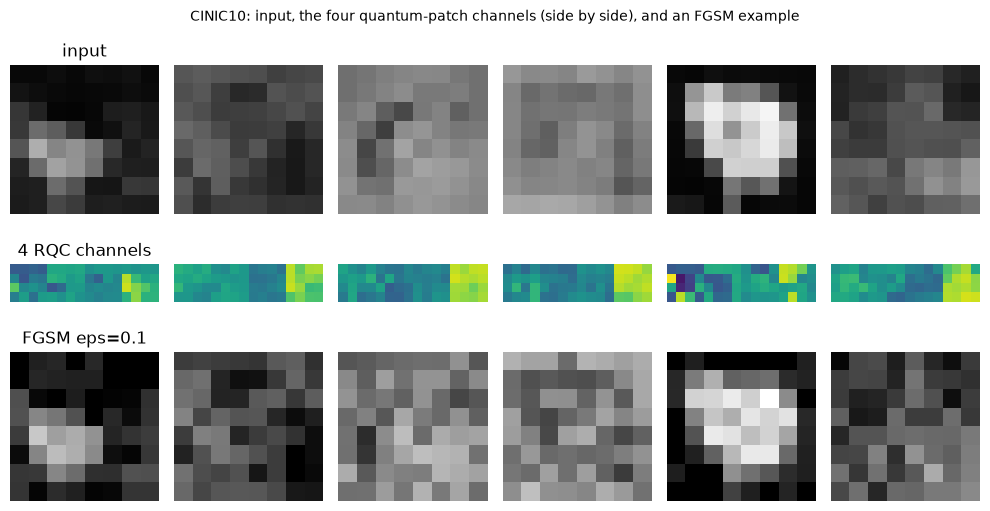

In [6]:
def input_gradient(model, x, y):
    x = x.clone().requires_grad_(True)
    loss = F.cross_entropy(model(x), y, reduction="sum")
    (g,) = torch.autograd.grad(loss, x)
    return g

def fgsm(model, x, y, eps):
    """Eq. 2 of the paper: x' = x + eps * sign(grad_x J), white box, clipped to the valid pixel range [0, 1]."""
    if eps == 0:
        return x.clone()
    return (x + eps * input_gradient(model, x, y).sign()).clamp(0, 1).detach()

def pgd(model, x, y, eps, steps, seed):
    """Projected gradient descent (Madry et al.): random start in the eps-ball, step size 2.5*eps/steps, l_inf projection."""
    g = torch.Generator().manual_seed(seed)
    xa = (x + eps * (2 * torch.rand(x.shape, generator=g, dtype=DTYPE) - 1)).clamp(0, 1)
    alpha = 2.5 * eps / steps
    for _ in range(steps):
        xa = xa + alpha * input_gradient(model, xa, y).sign()
        xa = torch.min(torch.max(xa, x - eps), x + eps).clamp(0, 1).detach()
    return xa

@torch.no_grad()
def predict(model, x, bs=100):
    return torch.cat([model(x[i:i + bs]).argmax(1) for i in range(0, len(x), bs)])

def attack_batched(fn, model, x, y, bs=100):
    return torch.cat([fn(model, x[i:i + bs], y[i:i + bs]) for i in range(0, len(x), bs)])

def attack_metrics(model, x, y, x_adv):
    """Adversarial accuracy AA (Eq. 5), attack success rate ASR = share of adversarial examples that are misclassified
    (the reading of Eq. 6 that matches the paper's text), and ASR_flip = share of the originally correct samples that flip."""
    p_clean, p_adv = predict(model, x), predict(model, x_adv)
    ok = p_clean == y
    return dict(AA=float((p_adv == y).double().mean() * 100),
                ASR=float((p_adv != y).double().mean() * 100),
                ASR_flip=float((p_adv[ok] != y[ok]).double().mean() * 100) if ok.any() else float("nan"))

# quick look: input images, the four quantum-patch channels (cf. paper Fig. 7) and FGSM examples (for an untrained model)
_d = DATA[DATASETS[-1]]
_x = torch.tensor(_d["Xtr"][:6], dtype=DTYPE); _y = torch.tensor(_d["ytr"][:6])
_m = QuantumClassifier(True, SEED)
_xa = fgsm(_m, _x, _y, 0.1)
fig, ax = plt.subplots(3, 6, figsize=(10, 5.2))
chan = _m.patches(_x).detach().numpy()
for i in range(6):
    ax[0, i].imshow(_x[i], cmap="gray", vmin=0, vmax=1); ax[0, i].set_title("input" if i == 0 else "")
    ax[1, i].imshow(chan[i].transpose(1, 0, 2).reshape(IMG // 2, -1), cmap="viridis", vmin=0, vmax=1)
    ax[1, i].set_title("4 RQC channels" if i == 0 else "")
    ax[2, i].imshow(_xa[i], cmap="gray", vmin=0, vmax=1); ax[2, i].set_title("FGSM eps=0.1" if i == 0 else "")
for a in ax.ravel(): a.axis("off")
plt.suptitle(f"{DATASETS[-1]}: input, the four quantum-patch channels (side by side), and an FGSM example", fontsize=10)
plt.tight_layout(); plt.show()
del _d, _x, _y, _m, _xa


## 4. Training: plain, with quantum patches, and with adversarial training

Three models are trained for every dataset and seed, always on the same clean training images:

* **plain**: the quantum classifier alone (the paper's "non-RQC" model);
* **rqc**: the same classifier fed with the image plus the four quantum-patch channels (the paper's proposal);
* **advtrain**: the plain classifier trained on clean and FGSM images (eps = 0.1), the baseline of the paper's ablation study.

After training, each model is attacked on the held-out test images with FGSM at every epsilon of `EPS_GRID` and with PGD at `EPS_MAIN`. The weights after epoch 1 are kept to reproduce the "first epoch" fidelity curve of Fig. 10.
In FAST mode the whole cell takes about 2.5 minutes; the committed full run prints its own total below.


In [7]:
def train_model(model, Xtr, ytr, seed, adv_train=False, tag=""):
    """Adam on cross-entropy. adv_train=True is the paper's ablation baseline: every mini-batch is extended with FGSM
    examples (eps = ADV_TRAIN_EPS) crafted against the current model. Returns history and the weights after epoch 1."""
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    g = torch.Generator().manual_seed(seed)
    n = len(Xtr); hist = dict(loss=[], lip=[]); snap1 = None
    t0 = time.time()
    for ep in range(1, EPOCHS + 1):
        perm = torch.randperm(n, generator=g); ep_loss = 0.0
        for i in range(0, n, BATCH):
            idx = perm[i:i + BATCH]; xb, yb = Xtr[idx], ytr[idx]
            if adv_train:
                xb = torch.cat([xb, fgsm(model, xb, yb, ADV_TRAIN_EPS)]); yb = torch.cat([yb, yb])
            opt.zero_grad()
            loss = F.cross_entropy(model(xb), yb)
            loss.backward(); opt.step()
            ep_loss += float(loss) * len(idx)
        hist["loss"].append(ep_loss / n); hist["lip"].append(model.lipschitz_bound())
        if ep == 1:
            snap1 = copy.deepcopy(model.state_dict())
        if ep == 1 or ep % 5 == 0 or ep == EPOCHS:
            print(f"    {tag} epoch {ep:3d}/{EPOCHS}  loss {hist['loss'][-1]:.4f}  Lipschitz bound {hist['lip'][-1]:.2f}  ({time.time()-t0:.0f}s)")
    return hist, snap1, time.time() - t0

def evaluate(model, X, y, seed):
    out = dict(clean=float((predict(model, X) == y).double().mean() * 100))
    for eps in EPS_GRID:
        xa = attack_batched(lambda m, a, b: fgsm(m, a, b, eps), model, X, y)
        out[f"fgsm_{eps}"] = attack_metrics(model, X, y, xa)
        if eps == EPS_MAIN:
            # empirical Lipschitz ratio ||f(x') - f(x)|| / ||x' - x||_2 on the eps = EPS_MAIN examples
            with torch.no_grad():
                d_out = (model(xa) - model(X)).norm(dim=1); d_in = (xa - X).flatten(1).norm(dim=1)
            out["lip_emp"] = float((d_out / d_in.clamp_min(1e-12)).mean())
    xp = attack_batched(lambda m, a, b: pgd(m, a, b, EPS_MAIN, PGD_STEPS, seed), model, X, y)
    out["pgd"] = attack_metrics(model, X, y, xp)
    return out

def mean_fidelity(model_state, use_rqc, seed, X, y, eps_list):
    """Average fidelity |<psi_adv|psi_clean>|^2 of the final (pre-measurement) quantum states for clean vs FGSM inputs."""
    m = QuantumClassifier(use_rqc, seed); m.load_state_dict(model_state)
    res = []
    for eps in eps_list:
        xa = attack_batched(lambda mm, a, b: fgsm(mm, a, b, eps), m, X, y)
        with torch.no_grad():
            s0 = torch.cat([m.state(X[i:i + 100]) for i in range(0, len(X), 100)])
            s1 = torch.cat([m.state(xa[i:i + 100]) for i in range(0, len(X), 100)])
        res.append(float((s0.conj() * s1).sum(1).abs().pow(2).mean()))
    return res

VARIANTS = [("plain", False, False), ("rqc", True, False), ("advtrain", False, True)]   # name, use_rqc, adversarial training
RESULTS, HISTORY, SNAPS, MODELS = {}, {}, {}, {}
t_all = time.time()
for dname in DATASETS:
    d = DATA[dname]
    Xtr = torch.tensor(d["Xtr"], dtype=DTYPE); ytr = torch.tensor(d["ytr"])
    Xte = torch.tensor(d["Xte"], dtype=DTYPE); yte = torch.tensor(d["yte"])
    for seed in SEEDS:
        for vname, use_rqc, adv in VARIANTS:
            key = (dname, vname, seed)
            torch.manual_seed(seed)
            model = QuantumClassifier(use_rqc, seed)
            print(f"[{dname} | {vname} | seed {seed}]")
            hist, snap1, secs = train_model(model, Xtr, ytr, seed, adv_train=adv, tag=vname)
            t1 = time.time(); res = evaluate(model, Xte, yte, seed); res["train_s"] = secs; res["eval_s"] = time.time() - t1
            res["train_acc"] = float((predict(model, Xtr) == ytr).double().mean() * 100)
            RESULTS[key], HISTORY[key], SNAPS[key] = res, hist, snap1
            MODELS[key] = copy.deepcopy(model.state_dict())
            print(f"    clean test acc {res['clean']:.1f}% | FGSM eps={EPS_MAIN}: AA {res[f'fgsm_{EPS_MAIN}']['AA']:.1f}%  "
                  f"ASR {res[f'fgsm_{EPS_MAIN}']['ASR']:.1f}% | PGD ASR {res['pgd']['ASR']:.1f}% | train {secs:.0f}s")
print(f"\nAll quantum models trained and attacked in {(time.time()-t_all)/60:.1f} min")


[MNIST | plain | seed 42]


    plain epoch   1/25  loss 0.5661  Lipschitz bound 64.34  (2s)


    plain epoch   5/25  loss 0.0630  Lipschitz bound 59.27  (8s)


    plain epoch  10/25  loss 0.0350  Lipschitz bound 54.58  (14s)


    plain epoch  15/25  loss 0.0237  Lipschitz bound 52.63  (21s)


...

    advtrain epoch  10/25  loss 0.7492  Lipschitz bound 16.21  (26s)


    advtrain epoch  15/25  loss 0.7009  Lipschitz bound 5.88  (39s)


    advtrain epoch  20/25  loss 0.6951  Lipschitz bound 2.74  (53s)


    advtrain epoch  25/25  loss 0.6937  Lipschitz bound 1.52  (67s)


    clean test acc 54.0% | FGSM eps=0.1: AA 2.0%  ASR 98.0% | PGD ASR 100.0% | train 67s

All quantum models trained and attacked in 40.2 min


## 5. Results: the paper's Table 1, re-computed

The table below is the equivalent of the paper's Table 1 (FGSM, epsilon = 0.1). `clean acc` is the accuracy on untouched test images, `AA` the accuracy under attack, `ASR` the share of attacked
images that are wrong. Mean +- standard deviation over the seeds (a test set of 200 images has a binomial standard error of about 3 accuracy points, so differences of a few points are noise).
The confusion matrices (positive class = the second class: digit 1 or dog) show *how* the errors change under attack.


Table 1 analogue: FGSM eps = 0.1, seeds [42, 43, 44], 200 test images per dataset (+- is the std over seeds)


,dataset,model,clean acc %,AA @eps=0.1 %,ASR @eps=0.1 %,ASR of correct %,PGD-10 ASR %,train acc %,train s
0,MNIST,quantum classifier,99.0 +- 0.4,85.5 +- 2.9,14.5 +- 2.9,13.6 +- 3.2,16.2 +- 2.3,100.0 +- 0.0,35 +- 2
1,MNIST,+ quantum patches (RQC),99.0 +- 0.0,79.5 +- 3.3,20.5 +- 3.3,19.7 +- 3.4,24.7 +- 2.1,100.0 +- 0.0,77 +- 1
2,MNIST,adversarial training (ablation baseline),99.0 +- 0.4,95.2 +- 0.6,4.8 +- 0.6,3.9 +- 0.3,4.8 +- 0.6,99.6 +- 0.0,67 +- 2
3,CIFAR10,quantum classifier,55.8 +- 3.7,0.0 +- 0.0,100.0 +- 0.0,100.0 +- 0.0,100.0 +- 0.0,86.5 +- 1.1,36 +- 1
4,CIFAR10,+ quantum patches (RQC),57.2 +- 1.2,0.2 +- 0.2,99.8 +- 0.2,99.7 +- 0.4,100.0 +- 0.0,93.1 +- 3.7,75 +- 1
5,CIFAR10,adversarial training (ablation baseline),51.5 +- 3.5,5.7 +- 6.6,94.3 +- 6.6,88.8 +- 12.9,95.3 +- 5.9,52.8 +- 3.3,69 +- 1
6,CINIC10,quantum classifier,49.3 +- 1.4,0.0 +- 0.0,100.0 +- 0.0,100.0 +- 0.0,100.0 +- 0.0,80.8 +- 2.7,34 +- 1
7,CINIC10,+ quantum patches (RQC),47.0 +- 1.1,0.0 +- 0.0,100.0 +- 0.0,100.0 +- 0.0,100.0 +- 0.0,85.8 +- 6.6,74 +- 1
8,CINIC10,adversarial training (ablation baseline),52.3 +- 2.7,14.0 +- 11.5,86.0 +- 11.5,72.1 +- 24.1,87.5 +- 11.6,59.0 +- 0.4,68 +- 1


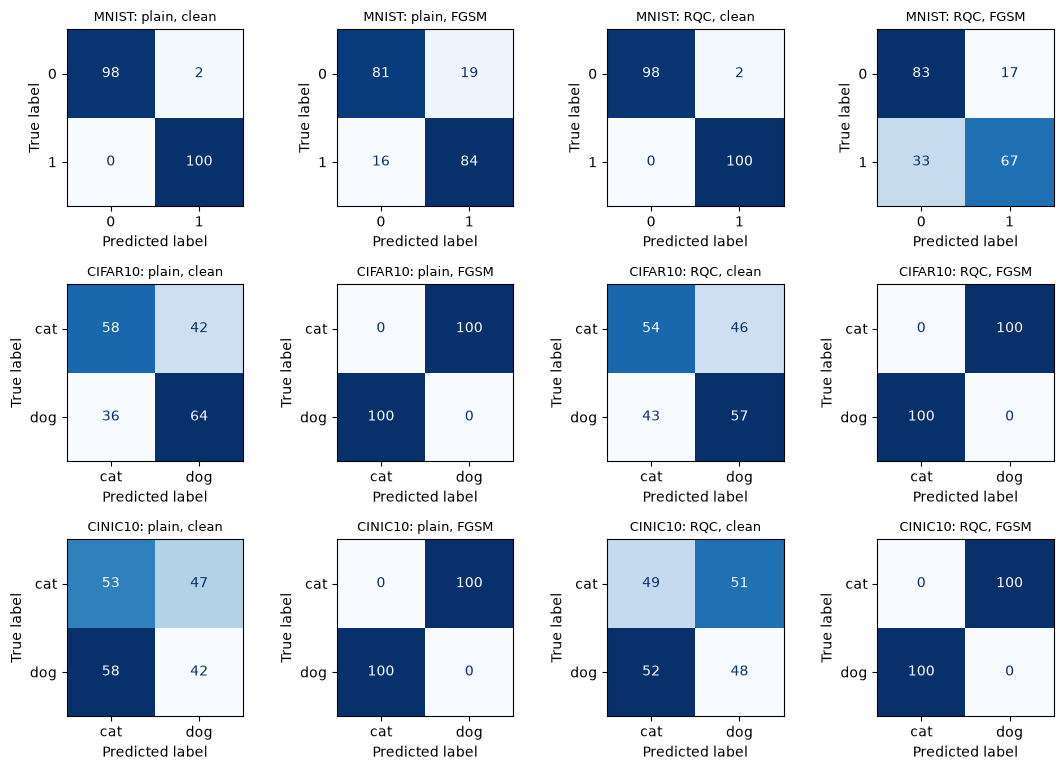

In [8]:
VNAME = {"plain": "quantum classifier", "rqc": "+ quantum patches (RQC)", "advtrain": "adversarial training (ablation baseline)"}

def collect(dname, vname, getter):
    vals = np.array([getter(RESULTS[(dname, vname, s)]) for s in SEEDS], dtype=float)
    return vals.mean(), (vals.std(ddof=0) if len(vals) > 1 else 0.0)

def ms(m_s, nd=1):
    return f"{m_s[0]:.{nd}f} +- {m_s[1]:.{nd}f}" if len(SEEDS) > 1 else f"{m_s[0]:.{nd}f}"

rows = []
for dname in DATASETS:
    for vname in ["plain", "rqc", "advtrain"]:
        k = f"fgsm_{EPS_MAIN}"
        rows.append({"dataset": dname, "model": VNAME[vname],
                     "clean acc %": ms(collect(dname, vname, lambda r: r["clean"])),
                     f"AA @eps={EPS_MAIN} %": ms(collect(dname, vname, lambda r: r[k]["AA"])),
                     f"ASR @eps={EPS_MAIN} %": ms(collect(dname, vname, lambda r: r[k]["ASR"])),
                     "ASR of correct %": ms(collect(dname, vname, lambda r: r[k]["ASR_flip"])),
                     f"PGD-{PGD_STEPS} ASR %": ms(collect(dname, vname, lambda r: r["pgd"]["ASR"])),
                     "train acc %": ms(collect(dname, vname, lambda r: r["train_acc"])),
                     "train s": ms(collect(dname, vname, lambda r: r["train_s"]), 0)})
TABLE1 = pd.DataFrame(rows)
print(f"Table 1 analogue: FGSM eps = {EPS_MAIN}, seeds {SEEDS}, {N_TEST_PER_CLASS*2} test images per dataset "
      f"(+- is the std over seeds)")
display(TABLE1)

# confusion matrices for the first seed: clean vs FGSM, plain vs quantum patches. Positive class = class 1 (digit 1 / dog).
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
s0 = SEEDS[0]
fig, axes = plt.subplots(len(DATASETS), 4, figsize=(11, 2.6 * len(DATASETS)))
axes = np.atleast_2d(axes)
for r, dname in enumerate(DATASETS):
    d = DATA[dname]; X = torch.tensor(d["Xte"], dtype=DTYPE); y = torch.tensor(d["yte"])
    for c, (vname, adv) in enumerate([("plain", False), ("plain", True), ("rqc", False), ("rqc", True)]):
        m = QuantumClassifier(vname == "rqc", s0); m.load_state_dict(MODELS[(dname, vname, s0)])
        xin = attack_batched(lambda mm, a, b: fgsm(mm, a, b, EPS_MAIN), m, X, y) if adv else X
        cm = confusion_matrix(y.numpy(), predict(m, xin).numpy(), labels=[0, 1])
        ConfusionMatrixDisplay(cm, display_labels=[d["names"][0][:6], d["names"][1][:6]]).plot(ax=axes[r, c], colorbar=False, cmap="Blues")
        axes[r, c].set_title(f"{dname}: {'plain' if vname=='plain' else 'RQC'}, {'FGSM' if adv else 'clean'}", fontsize=9)
plt.tight_layout(); plt.show()


## 6. How robust is it as the attack gets stronger?

The paper fixes epsilon = 0.1 for Table 1 and sweeps epsilon only for the fidelity plot. Here the adversarial accuracy is drawn over the whole epsilon grid. A model at the dotted 50 % line is at chance level.


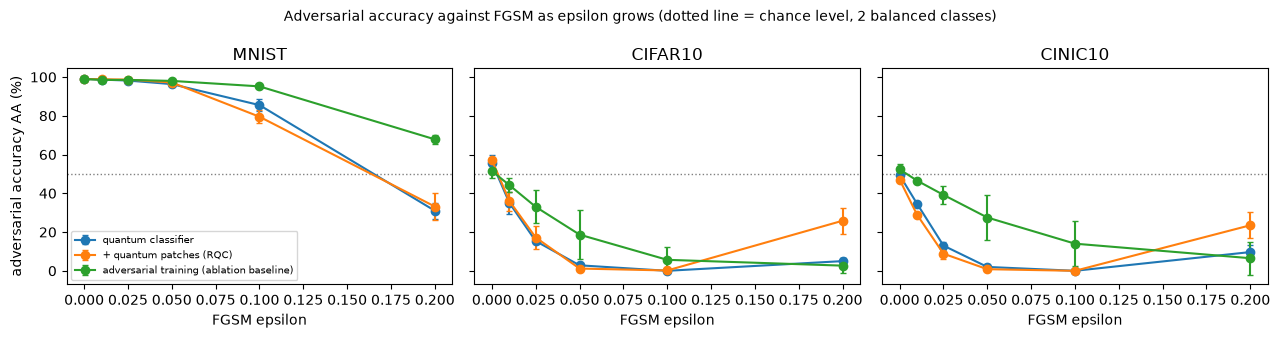

MNIST    clean accuracy  99.0 ->  99.0 with RQC (+0.0) | FGSM ASR  14.5 ->  20.5 (+6.0)
CIFAR10  clean accuracy  55.8 ->  57.2 with RQC (+1.3) | FGSM ASR 100.0 ->  99.8 (-0.2)
CINIC10  clean accuracy  49.3 ->  47.0 with RQC (-2.3) | FGSM ASR 100.0 -> 100.0 (+0.0)


In [9]:
fig, axes = plt.subplots(1, len(DATASETS), figsize=(4.3 * len(DATASETS), 3.4), sharey=True)
axes = np.atleast_1d(axes)
colors = {"plain": "tab:blue", "rqc": "tab:orange", "advtrain": "tab:green"}
for ax, dname in zip(axes, DATASETS):
    for vname in ["plain", "rqc", "advtrain"]:
        m_ = np.array([collect(dname, vname, lambda r, e=e: r[f"fgsm_{e}"]["AA"]) for e in EPS_GRID])
        ax.errorbar(EPS_GRID, m_[:, 0], yerr=m_[:, 1], marker="o", capsize=2, color=colors[vname], label=VNAME[vname])
    ax.axhline(50, color="grey", ls=":", lw=1); ax.set_title(dname); ax.set_xlabel("FGSM epsilon")
axes[0].set_ylabel("adversarial accuracy AA (%)"); axes[0].legend(fontsize=7)
plt.suptitle("Adversarial accuracy against FGSM as epsilon grows (dotted line = chance level, 2 balanced classes)", fontsize=10)
plt.tight_layout(); plt.show()

# what the defence changes on clean data, in one line per dataset
for dname in DATASETS:
    cp, cr = collect(dname, "plain", lambda r: r["clean"]), collect(dname, "rqc", lambda r: r["clean"])
    ap = collect(dname, "plain", lambda r: r[f"fgsm_{EPS_MAIN}"]["ASR"]); ar = collect(dname, "rqc", lambda r: r[f"fgsm_{EPS_MAIN}"]["ASR"])
    print(f"{dname:8s} clean accuracy {cp[0]:5.1f} -> {cr[0]:5.1f} with RQC ({cr[0]-cp[0]:+.1f}) | "
          f"FGSM ASR {ap[0]:5.1f} -> {ar[0]:5.1f} ({ar[0]-ap[0]:+.1f})")


## 7. Ablation: Lipschitz bound and average fidelity (the paper's Fig. 9 and Fig. 10)

The paper compares the quantum-patch model with the adversarially trained baseline on CIFAR-10 using two numbers:

* the **Lipschitz bound** of Eq. 8, `L = 2 ||M|| sum_j ||omega_j|| ||H_j||`, where `M` is the observable (Pauli Z, norm 1), `omega_j` the scale of an encoding gate (`ENC_SCALE * enc_b` here) and `H_j` its generator (`Y/2`, norm 1/2).
  It depends only on the encoding scales, grows with the number of encoding gates, and a smaller number means a smoother model. Because the defended model has **twice as many encoding gates** (32 blocks against 16),
  its bound is larger by construction unless the learned scales are much smaller; the table therefore also lists the mean scale per block and an *empirical* ratio `||f(x') - f(x)|| / ||x' - x||_2` on the FGSM examples.
* the **average fidelity** `|<psi_adv|psi_clean>|^2` between the pre-measurement quantum states of the clean image and its FGSM version; closer to 1 means the circuit's state barely moves.


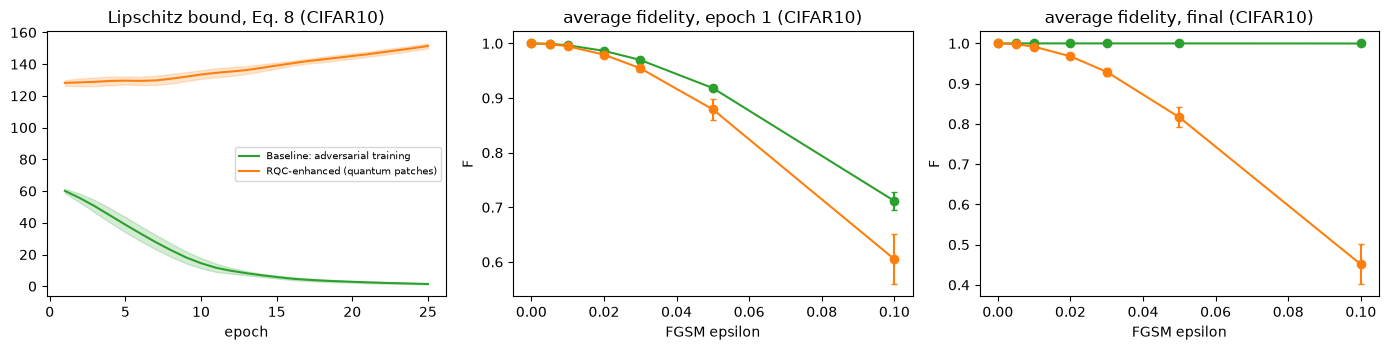

,model,Lipschitz bound (last epoch),mean |enc| per block,empirical Lipschitz ratio,"F @eps=0.02, epoch 1","mean F over eps>0, epoch 1","F @eps=0.02, final","mean F over eps>0, final"
0,adversarial training (ablation baseline),1.4,0.022,0.019 +- 0.007,0.986,0.930,1.000,1.000
1,+ quantum patches (RQC),151.5,1.183,2.872 +- 0.118,0.979,0.902,0.968,0.859


In [10]:
ABL_DATASET = "CIFAR10" if "CIFAR10" in DATASETS else DATASETS[0]      # paper Fig. 9 and Fig. 10 use CIFAR-10
FID_EPS = [0.0, 0.005, 0.01, 0.02, 0.03, 0.05, 0.1]                            # CHOICE: the paper plots "gradually increasing" eps

d = DATA[ABL_DATASET]; Xte = torch.tensor(d["Xte"], dtype=DTYPE); yte = torch.tensor(d["yte"])
fid = {}                                                                  # (variant, stage) -> mean over seeds of F(eps)
for vname, use_rqc in [("advtrain", False), ("rqc", True)]:
    for stage, store in [("epoch 1", SNAPS), ("final", MODELS)]:
        curves = [mean_fidelity(store[(ABL_DATASET, vname, s)], use_rqc, s, Xte, yte, FID_EPS) for s in SEEDS]
        fid[(vname, stage)] = np.array(curves)

fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
for vname, lab in [("advtrain", "Baseline: adversarial training"), ("rqc", "RQC-enhanced (quantum patches)")]:
    L = np.array([HISTORY[(ABL_DATASET, vname, s)]["lip"] for s in SEEDS])
    ax[0].plot(np.arange(1, EPOCHS + 1), L.mean(0), color=colors[vname], label=lab)
    ax[0].fill_between(np.arange(1, EPOCHS + 1), L.mean(0) - L.std(0), L.mean(0) + L.std(0), color=colors[vname], alpha=.2)
    for a, stage in zip(ax[1:], ["epoch 1", "final"]):
        f_ = fid[(vname, stage)]
        a.errorbar(FID_EPS, f_.mean(0), yerr=f_.std(0), marker="o", capsize=2, color=colors[vname], label=lab)
        a.set_title(f"average fidelity, {stage} ({ABL_DATASET})"); a.set_xlabel("FGSM epsilon"); a.set_ylabel("F")
ax[0].set_title(f"Lipschitz bound, Eq. 8 ({ABL_DATASET})"); ax[0].set_xlabel("epoch"); ax[0].legend(fontsize=7)
plt.tight_layout(); plt.show()

abl = []
for vname in ["advtrain", "rqc"]:
    abl.append({"model": VNAME[vname],
                "Lipschitz bound (last epoch)": f"{np.mean([HISTORY[(ABL_DATASET, vname, s)]['lip'][-1] for s in SEEDS]):.1f}",
                "mean |enc| per block": f"{np.mean([MODELS[(ABL_DATASET, vname, s)]['enc'].abs().mean().item() for s in SEEDS]):.3f}",
                "empirical Lipschitz ratio": ms(collect(ABL_DATASET, vname, lambda r: r["lip_emp"]), 3),
                f"F @eps=0.02, epoch 1": f"{fid[(vname,'epoch 1')][:, FID_EPS.index(0.02)].mean():.3f}",
                "mean F over eps>0, epoch 1": f"{fid[(vname,'epoch 1')][:, 1:].mean():.3f}",
                f"F @eps=0.02, final": f"{fid[(vname,'final')][:, FID_EPS.index(0.02)].mean():.3f}",
                "mean F over eps>0, final": f"{fid[(vname,'final')][:, 1:].mean():.3f}"})
ABL = pd.DataFrame(abl)
display(ABL)


## 7b. Sensitivity to the encoding angle

The paper does not say how pixels become angles. The main runs use the pixel value itself as the angle (`ENC_SCALE = 1`). The next cell repeats the plain and the defended model, for one seed and the MNIST and CIFAR-10 tasks, with the angle range [0, pi] (`ENC_SCALE = pi`) that is
also common, and compares the two settings. (The main setting is restored afterwards.)


[sensitivity ENC_SCALE=3.14 | MNIST | plain | seed 42]


    plain epoch   1/25  loss 0.6894  Lipschitz bound 202.31  (1s)


    plain epoch   5/25  loss 0.2847  Lipschitz bound 182.75  (8s)


    plain epoch  10/25  loss 0.1581  Lipschitz bound 162.46  (15s)


    plain epoch  15/25  loss 0.1068  Lipschitz bound 143.15  (21s)


...

    rqc epoch  15/25  loss 0.2648  Lipschitz bound 399.38  (45s)


    rqc epoch  20/25  loss 0.2342  Lipschitz bound 400.41  (59s)


    rqc epoch  25/25  loss 0.2103  Lipschitz bound 401.61  (76s)


sensitivity run took 5.8 min; ENC_SCALE restored to 1.0


,dataset,model,clean % (scale 1),clean % (scale 3.14),ASR@0.025 % (1),ASR@0.025 % (3.14),ASR@0.1 % (1),ASR@0.1 % (3.14),PGD ASR % (1),PGD ASR % (3.14)
0,MNIST,quantum classifier,99.0,99.0,1.0,6.5,17.5,71.0,18.5,98.0
1,MNIST,+ quantum patches (RQC),99.0,87.0,1.0,47.0,25.0,69.0,27.5,100.0
2,CIFAR10,quantum classifier,61.0,55.5,83.0,99.5,100.0,60.0,100.0,100.0
3,CIFAR10,+ quantum patches (RQC),55.5,53.0,89.5,100.0,100.0,48.5,100.0,100.0


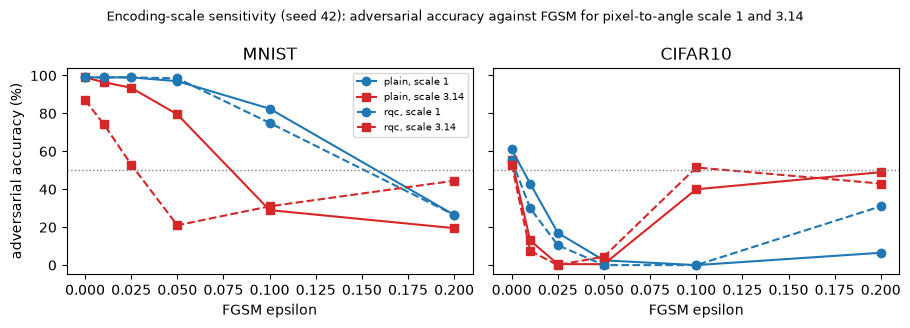

In [11]:
SENS_ENC = math.pi                      # the alternative encoding scale: pixels in [0,1] -> angles in [0, pi]
SENS_DATASETS = [n for n in ["MNIST", "CIFAR10"] if n in DATASETS]
ENC_MAIN = ENC_SCALE
SENS = {}
t0 = time.time()
try:
    ENC_SCALE = SENS_ENC                # the circuit reads this global, so everything below uses the alternative scale
    for dname in SENS_DATASETS:
        d = DATA[dname]; seed = SEEDS[0]
        Xtr = torch.tensor(d["Xtr"], dtype=DTYPE); ytr = torch.tensor(d["ytr"])
        Xte = torch.tensor(d["Xte"], dtype=DTYPE); yte = torch.tensor(d["yte"])
        for vname, use_rqc in [("plain", False), ("rqc", True)]:
            torch.manual_seed(seed); model = QuantumClassifier(use_rqc, seed)
            print(f"[sensitivity ENC_SCALE={SENS_ENC:.2f} | {dname} | {vname} | seed {seed}]")
            train_model(model, Xtr, ytr, seed, tag=vname)
            SENS[(dname, vname)] = evaluate(model, Xte, yte, seed)
finally:
    ENC_SCALE = ENC_MAIN                # always restore the main setting
print(f"sensitivity run took {(time.time()-t0)/60:.1f} min; ENC_SCALE restored to {ENC_SCALE}")

rows = []
for dname in SENS_DATASETS:
    for vname in ["plain", "rqc"]:
        a = RESULTS[(dname, vname, SEEDS[0])]; b_ = SENS[(dname, vname)]
        rows.append({"dataset": dname, "model": VNAME[vname],
                     f"clean % (scale {ENC_MAIN:g})": f"{a['clean']:.1f}", f"clean % (scale {SENS_ENC:.2f})": f"{b_['clean']:.1f}",
                     f"ASR@0.025 % ({ENC_MAIN:g})": f"{a['fgsm_0.025']['ASR']:.1f}", f"ASR@0.025 % ({SENS_ENC:.2f})": f"{b_['fgsm_0.025']['ASR']:.1f}",
                     f"ASR@0.1 % ({ENC_MAIN:g})": f"{a[f'fgsm_{EPS_MAIN}']['ASR']:.1f}", f"ASR@0.1 % ({SENS_ENC:.2f})": f"{b_[f'fgsm_{EPS_MAIN}']['ASR']:.1f}",
                     f"PGD ASR % ({ENC_MAIN:g})": f"{a['pgd']['ASR']:.1f}", f"PGD ASR % ({SENS_ENC:.2f})": f"{b_['pgd']['ASR']:.1f}"})
display(pd.DataFrame(rows))

fig, axes = plt.subplots(1, len(SENS_DATASETS), figsize=(4.6 * len(SENS_DATASETS), 3.3), sharey=True)
axes = np.atleast_1d(axes)
for ax, dname in zip(axes, SENS_DATASETS):
    for vname, ls in [("plain", "-"), ("rqc", "--")]:
        ax.plot(EPS_GRID, [RESULTS[(dname, vname, SEEDS[0])][f"fgsm_{e}"]["AA"] for e in EPS_GRID], ls, marker="o", color="tab:blue",
                label=f"{vname}, scale {ENC_MAIN:g}")
        ax.plot(EPS_GRID, [SENS[(dname, vname)][f"fgsm_{e}"]["AA"] for e in EPS_GRID], ls, marker="s", color="tab:red",
                label=f"{vname}, scale {SENS_ENC:.2f}")
    ax.axhline(50, color="grey", ls=":", lw=1); ax.set_title(dname); ax.set_xlabel("FGSM epsilon")
axes[0].set_ylabel("adversarial accuracy (%)"); axes[0].legend(fontsize=7)
plt.suptitle(f"Encoding-scale sensitivity (seed {SEEDS[0]}): adversarial accuracy against FGSM for pixel-to-angle scale {ENC_MAIN:g} and {SENS_ENC:.2f}", fontsize=9)
plt.tight_layout(); plt.show()


## 8. Classical baselines on the identical inputs

The same 8 x 8 grey images go into scikit-learn models (random forest, RBF SVM, logistic regression) and a small classical network (64-16-2, tanh), which is also attacked with FGSM. The point is not to beat the quantum
classifier but to calibrate the task: with 240 training images of a 64-pixel cat or dog, a classical model is close to chance too, and a classical network is just as easy to fool.


In [12]:
class TinyMLP(torch.nn.Module):
    """Classical reference with a similar parameter budget to the quantum classifier: 64 -> 16 -> 2 (about 1,200 weights)."""
    def __init__(self, seed):
        super().__init__()
        g = torch.Generator().manual_seed(seed)
        self.l1 = torch.nn.Linear(IMG * IMG, 16).double(); self.l2 = torch.nn.Linear(16, 2).double()
        for l in (self.l1, self.l2):
            torch.nn.init.normal_(l.weight, std=0.3, generator=g); torch.nn.init.zeros_(l.bias)
    def forward(self, img):
        return self.l2(torch.tanh(self.l1(img.flatten(1))))

crow = []
for dname in DATASETS:
    d = DATA[dname]
    Xtr_, ytr_ = d["Xtr"].reshape(len(d["Xtr"]), -1), d["ytr"]; Xte_, yte_ = d["Xte"].reshape(len(d["Xte"]), -1), d["yte"]
    Xtr_t = torch.tensor(d["Xtr"], dtype=DTYPE); ytr_t = torch.tensor(d["ytr"])
    Xte_t = torch.tensor(d["Xte"], dtype=DTYPE); yte_t = torch.tensor(d["yte"])
    accs = {"RandomForest": [], "SVC (rbf)": [], "LogReg": [], "TinyMLP": [], "TinyMLP FGSM AA": []}
    for seed in SEEDS:
        accs["RandomForest"].append(RandomForestClassifier(n_estimators=200, random_state=seed).fit(Xtr_, ytr_).score(Xte_, yte_) * 100)
        accs["SVC (rbf)"].append(SVC(kernel="rbf", C=1.0, random_state=seed).fit(Xtr_, ytr_).score(Xte_, yte_) * 100)
        accs["LogReg"].append(LogisticRegression(max_iter=2000, random_state=seed).fit(Xtr_, ytr_).score(Xte_, yte_) * 100)
        torch.manual_seed(seed); mlp = TinyMLP(seed); opt = torch.optim.Adam(mlp.parameters(), lr=0.02)
        for ep in range(100):                                      # CHOICE: 100 full-batch epochs
            opt.zero_grad(); F.cross_entropy(mlp(Xtr_t), ytr_t).backward(); opt.step()
        accs["TinyMLP"].append(float((predict(mlp, Xte_t) == yte_t).double().mean() * 100))
        xa = fgsm(mlp, Xte_t, yte_t, EPS_MAIN)
        accs["TinyMLP FGSM AA"].append(attack_metrics(mlp, Xte_t, yte_t, xa)["AA"])
    row = {"dataset": dname}
    for k, v in accs.items():
        row[k] = f"{np.mean(v):.1f}" + (f" +- {np.std(v):.1f}" if len(v) > 1 else "")
    row["quantum plain"] = ms(collect(dname, "plain", lambda r: r["clean"]))
    row["quantum + RQC"] = ms(collect(dname, "rqc", lambda r: r["clean"]))
    crow.append(row)
CLASSICAL = pd.DataFrame(crow)
print(f"Clean test accuracy (%) on the identical {IMG}x{IMG} grey inputs; last column of the MLP is its FGSM (eps={EPS_MAIN}) accuracy")
display(CLASSICAL)


Clean test accuracy (%) on the identical 8x8 grey inputs; last column of the MLP is its FGSM (eps=0.1) accuracy


,dataset,RandomForest,SVC (rbf),LogReg,TinyMLP,TinyMLP FGSM AA,quantum plain,quantum + RQC
0,MNIST,98.5 +- 0.0,98.5 +- 0.0,99.0 +- 0.0,99.7 +- 0.5,47.3 +- 0.8,99.0 +- 0.4,99.0 +- 0.0
1,CIFAR10,58.0 +- 1.2,60.5 +- 0.0,60.0 +- 0.0,55.3 +- 2.1,1.7 +- 0.5,55.8 +- 3.7,57.2 +- 1.2
2,CINIC10,45.5 +- 0.0,47.0 +- 0.0,50.0 +- 0.0,46.2 +- 0.6,0.3 +- 0.2,49.3 +- 1.4,47.0 +- 1.1


## 9. Side by side with the paper

Every checkable number of the paper is compared with this notebook. Rules: accuracy-type numbers are *reproduced* if they agree within 2 points; otherwise the verdict says *exceeded* (ours is larger) or *not reached*
(ours is smaller) together with the gap. "Change caused by RQC" rows test the sign (and, for ASR, the size) of the effect of the defence, which is the paper's actual claim. Claims without numbers or on data we do not have are marked *cannot be checked*.


In [13]:
TOL = 2.0     # accuracy points within which a number counts as reproduced (the factory's rule)
K = f"fgsm_{EPS_MAIN}"
# Paper Table 1 (epsilon = 0.1). Every cell of the table is a percentage; "AA" rows are clean accuracy, "ASR" rows are attack success.
PAPER = {
    "MNIST":   dict(clean_plain=100.0, clean_rqc=88.0, asr_plain=22.0,  asr_rqc=25.38),
    "CIFAR10": dict(clean_plain=48.0,  clean_rqc=45.0, asr_plain=89.8,  asr_rqc=68.45),
    "CINIC10": dict(clean_plain=57.0,  clean_rqc=47.0, asr_plain=94.23, asr_rqc=78.68),
}

def mean_of(dname, vname, getter):
    return collect(dname, vname, getter)[0]

def num_verdict(paper, ours, tol=TOL):
    gap = ours - paper
    if abs(gap) <= tol:
        return f"reproduced (gap {gap:+.1f})"
    return f"{'exceeded' if gap > 0 else 'not reached'} (gap {gap:+.1f})"

def noise(dname, getter):
    """Seed-to-seed standard deviation (larger of plain / RQC): effects smaller than this are not distinguishable from zero."""
    return max(collect(dname, "plain", getter)[1], collect(dname, "rqc", getter)[1])

def sign_verdict(paper_change, ours_change, nz):
    if abs(ours_change) <= max(nz, 1.0):
        return f"not reproduced (no change beyond seed noise, std {nz:.1f})"
    return "reproduced (same sign)" if np.sign(ours_change) == np.sign(paper_change) else "not reproduced (opposite sign)"

rows = []
for dname in DATASETS:
    p = PAPER[dname]
    cp, cr = mean_of(dname, "plain", lambda r: r["clean"]), mean_of(dname, "rqc", lambda r: r["clean"])
    ap, ar = mean_of(dname, "plain", lambda r: r[K]["ASR"]), mean_of(dname, "rqc", lambda r: r[K]["ASR"])
    rows += [
        (dname, "clean accuracy, quantum classifier", p["clean_plain"], cp, num_verdict(p["clean_plain"], cp)),
        (dname, "clean accuracy, with RQC", p["clean_rqc"], cr, num_verdict(p["clean_rqc"], cr)),
        (dname, "clean accuracy change caused by RQC", p["clean_rqc"] - p["clean_plain"], cr - cp,
         sign_verdict(p["clean_rqc"] - p["clean_plain"], cr - cp, noise(dname, lambda r: r["clean"]))),
        (dname, f"ASR at eps={EPS_MAIN}, quantum classifier", p["asr_plain"], ap, num_verdict(p["asr_plain"], ap)),
        (dname, f"ASR at eps={EPS_MAIN}, with RQC", p["asr_rqc"], ar, num_verdict(p["asr_rqc"], ar)),
    ]
    dp, dn = p["asr_rqc"] - p["asr_plain"], ar - ap
    same = np.sign(dn) == np.sign(dp)
    nz = noise(dname, lambda r: r[K]["ASR"])
    if abs(dn - dp) <= TOL:
        v = "reproduced"
    elif abs(dn) <= max(nz, 1.0):
        v = "not reproduced (no change beyond seed noise)"
    else:
        v = "same sign, size not reached" if same and abs(dn) < abs(dp) else "same sign, size exceeded" if same else "not reproduced (opposite sign)"
    rows.append((dname, "ASR change caused by RQC (pts)", dp, dn, v + f" (gap {dn - dp:+.1f})"))

# ablation claims on the CIFAR-10-like dataset
adv_asr = mean_of(ABL_DATASET, "advtrain", lambda r: r[K]["ASR"]); rqc_asr = mean_of(ABL_DATASET, "rqc", lambda r: r[K]["ASR"])
rows.append((ABL_DATASET, "RQC about as robust as adversarial training (ASR difference, pts)", "qualitative", rqc_asr - adv_asr,
             "reproduced" if rqc_asr - adv_asr <= TOL else "not reproduced (RQC is less robust)"))
L_adv = np.mean([HISTORY[(ABL_DATASET, "advtrain", s)]["lip"][-1] for s in SEEDS]); L_rqc = np.mean([HISTORY[(ABL_DATASET, "rqc", s)]["lip"][-1] for s in SEEDS])
rows.append((ABL_DATASET, "Lipschitz bound, RQC lower than adversarial training (paper: 0.571 vs 0.711)", "0.571 < 0.711",
             f"{L_rqc:.1f} vs {L_adv:.1f}", "reproduced" if L_rqc < L_adv else "not reproduced (RQC bound is higher; it has twice the encoding gates)"))
for stage in ["epoch 1", "final"]:
    fr, fa = fid[("rqc", stage)][:, 1:].mean(), fid[("advtrain", stage)][:, 1:].mean()      # mean fidelity over eps > 0
    rows.append((ABL_DATASET, f"average fidelity (mean over eps in (0, 0.1]) higher for RQC ({stage})", "RQC > baseline (Fig. 10)", f"{fr:.3f} vs {fa:.3f}",
                 "reproduced" if fr > fa else "not reproduced (RQC fidelity is lower)"))
rows += [("Plus-Minus", "Fig. 8: 4/4 clean, 0/4 attacked, 3/4 with RQC", "4/4, 0/4, 3/4", "-", "cannot be checked (dataset not public here; four-sample figure)"),
         ("QCNN", "RQC also helps a QCNN, less than the circuit-centric classifier", "qualitative", "-", "cannot be checked (no numbers, not implemented)"),
         ("all", "50 epochs, 48 h on four H100 GPUs, full-resolution images", "-", f"{EPOCHS} epochs, {IMG}x{IMG} grey", "not attempted (CPU budget)")]

COMPARE = pd.DataFrame(rows, columns=["dataset", "claim", "paper", "this notebook", "verdict"])
COMPARE["paper"] = COMPARE["paper"].map(lambda v: f"{v:.2f}" if isinstance(v, (float, np.floating)) else v)
COMPARE["this notebook"] = COMPARE["this notebook"].map(lambda v: f"{v:.2f}" if isinstance(v, (float, np.floating)) else v)
pd.set_option("display.max_colwidth", 90)
print("Paper (Table 1 of Tran et al.) against this notebook; 'exceeded' = our number is larger than the paper's, 'not reached' = smaller")
display(COMPARE)
print("\nVerdict counts:", COMPARE["verdict"].str.split(" \\(").str[0].value_counts().to_dict())


Paper (Table 1 of Tran et al.) against this notebook; 'exceeded' = our number is larger than the paper's, 'not reached' = smaller


,dataset,claim,paper,this notebook,verdict
0,MNIST,"clean accuracy, quantum classifier",100.00,99.00,reproduced (gap -1.0)
1,MNIST,"clean accuracy, with RQC",88.00,99.00,exceeded (gap +11.0)
2,MNIST,clean accuracy change caused by RQC,-12.00,0.00,"not reproduced (no change beyond seed noise, std 0.4)"
3,MNIST,"ASR at eps=0.1, quantum classifier",22.00,14.50,not reached (gap -7.5)
4,MNIST,"ASR at eps=0.1, with RQC",25.38,20.50,not reached (gap -4.9)
5,MNIST,ASR change caused by RQC (pts),3.38,6.00,"same sign, size exceeded (gap +2.6)"
6,CIFAR10,"clean accuracy, quantum classifier",48.00,55.83,exceeded (gap +7.8)
7,CIFAR10,"clean accuracy, with RQC",45.00,57.17,exceeded (gap +12.2)
8,CIFAR10,clean accuracy change caused by RQC,-3.00,1.33,"not reproduced (no change beyond seed noise, std 3.7)"
9,CIFAR10,"ASR at eps=0.1, quantum classifier",89.80,100.00,exceeded (gap +10.2)



Verdict counts: {'not reproduced': 8, 'exceeded': 7, 'reproduced': 3, 'not reached': 3, 'cannot be checked': 2, 'same sign, size exceeded': 1, 'not attempted': 1}


## 10. Reading the paper critically

* **A chance-level victim cannot show robustness.** The paper's clean accuracies on the binary CIFAR-10 and CINIC-10 tasks are 48 % and 57 % (45 % and 47 % with RQC): a two-class model at or below 50 % is guessing. Its "attack success rate" of 89.8 % then
  mostly measures that a gradient attack can push a barely informative classifier to the wrong label, and a drop to 68 % is not evidence that the model "knows" the images better. The same holds here: in the committed run our models reach only about 50 to 57 % test accuracy on cat vs dog
  (they fit the 240 training images, 81 to 93 % train accuracy, and do not generalise), and under FGSM at epsilon = 0.1 essentially every correct and every wrong prediction flips (ASR about 100 %), with or without quantum patches. Read the clean-accuracy column next to the ASR column before reading anything into a lower ASR.
* **The defence changes the model, not only the data.** In the paper's Fig. 7 the network input is the image plus four RQC channels; this is a feature transformation that can lower or raise sensitivity to pixel changes simply by changing the function that is learned. Only a white-box attack
  *through* the fixed quantum circuit tells whether it helps; an attack that ignores it (or a grey-box transfer attack) would overstate the robustness. The paper does not say which attacker it uses. Here the attack goes through the circuit, and on MNIST the defended model is *less* robust (ASR 14.5 % -> 20.5 %, higher in every seed), as the paper also observes.
* **Gradient masking and the shape of the attack.** PGD with ten steps is only slightly stronger than one FGSM step at epsilon = 0.1 in the main setting (for instance MNIST ASR about 16 % against 14.5 %), so there is no sign that the single step is masked. With the angle range [0, pi] (section 7b), however, FGSM becomes *weaker* as epsilon grows from 0.025 to 0.1, because the cosine-shaped
  loss surface of a rotation-encoded model wraps around and a large sign step jumps over the loss peak: an "improvement" in FGSM accuracy at one epsilon can be an attack artefact, which is why a sweep and PGD are worth running.
* **ASR is ambiguous.** Eq. 6 in the PDF is garbled; "attack success rate" can mean "adversarial examples that are wrong" or "originally correct examples that flip". Both are reported here; they differ a lot when clean accuracy is low.
* **Comparison with adversarial training.** The abstract says RQC data "provides a similar effect to models trained with adversarial data", but Table 1 has no adversarially trained row and the Lipschitz and fidelity figures compare against that baseline only through two curves.
  In our run the FGSM-adversarially-trained quantum classifier is clearly more robust on MNIST (ASR 4.8 %) but on CIFAR-10 and CINIC-10 it mostly collapses: its encoding scales shrink toward zero (the Lipschitz bound drops from 60 to about 1.4, section 7), it is near chance on clean images, and its fidelity trivially stays at 1. Lipschitz bounds from Eq. 8 also count encoding gates, so a model with more gates
  (the RQC model) is penalised by construction; neither number is a fair robustness comparison between these two models.
* **Reduced experiment.** 8 x 8 grey images, 240 training images and three seeds are a deliberately small replication; the standard error of any accuracy on 200 test images is about 3 points, which is larger than the 3-point drop the paper reports from RQC on CIFAR-10 clean accuracy. The qualitative claim that RQC lowers the ASR on CIFAR-10 and CINIC-10 therefore remains untested at the paper's scale (full-size colour images, 50 epochs, a better-trained victim).
* **One tuned hyper-parameter.** The pixel-to-angle scale was fixed to 1 after a pilot (disclosed in the table at the top). With scale pi all models are much more fragile (section 7b); the verdicts above would be even worse for the paper's CIFAR claims.
* **MNIST works against the story.** The paper reports no benefit on MNIST and explains it by "low-feature" data; with so few data sets and no ablation of the RQC depth or of the number of channels, this explanation is only a hypothesis. Also note that on MNIST the quantum classifier (AA 85.5 %) is more robust than the classical 64-16-2 network (AA 47 %) at the same epsilon; with one qubit-rotation per pixel and small angles, a bounded, nearly linear response is part of the explanation, so this is not evidence of a quantum advantage.

## 11. Exercises

1. **Encoding angle.** Set `ENC_SCALE = 3.14159` in the configuration cell (pixels become angles in [0, pi] rather than [0, 1]) and re-run the whole notebook. How do clean accuracy, FGSM ASR and PGD ASR change, and why can FGSM at a larger epsilon be *weaker* than at a smaller one (section 7b)?
2. **A different random circuit.** Change `RQC_LAYERS` (1, 2, 4) or replace `RandomLayers` by a Haar-random 16 x 16 unitary (`qml.QubitUnitary` with a matrix from `scipy.stats.unitary_group`). Does the effect of the defence depend on the circuit? Repeat with five seeds.
3. **A control for capacity.** The defended model has twice as many blocks as the plain one. Build a plain model with 32 blocks (for instance by uploading the image twice) and test whether the benefit comes from quantum patches or only from capacity.
4. **Grey-box attack.** Craft FGSM examples against the plain model and feed them to the defended model (transfer attack). Is the defended model more robust against attacks it never differentiated through than against white-box attacks?
5. **Bigger images.** Raise `IMG` to 16 (the patch counts follow automatically) and lower the training set if needed. Does the paper's "high-feature datasets benefit more" story show up when the images have more pixels?
